# **Bone Fracture Detection from X-Ray Images Using CNN**

## Environment & Basic Libraries

In [7]:
!unzip /content/archive.zip -d /content/fracture_dataset

Streaming output truncated to the last 5000 lines.
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated2-rotated3-rotated3.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated2-rotated3.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated2.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated1-rotated1.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated1-rotated2.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated1-rotated3.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated1.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated2-rotated1.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated2-rotated2.jpg  
  inflating: /content/fracture_dataset/data/train/fractured/99-rotated3-rotated2-rotated3.jpg  
  inflating: /content/fra

In [8]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = "/content/fracture_dataset"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

print("Dataset exists:", os.path.isdir(DATA_DIR))
print("Class folders:", os.listdir(DATA_DIR))

Dataset exists: True
Class folders: ['data']


In [20]:
train_dir = os.path.join(DATA_DIR, "data", "train")
val_dir = os.path.join(DATA_DIR, "data", "val")

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

temp_ds = keras.utils.image_dataset_from_directory(
    val_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

class_names = train_ds.class_names
print("Class names:", class_names)

Found 8863 files belonging to 2 classes.
Found 600 files belonging to 2 classes.
Class names: ['fractured', 'not fractured']


In [21]:
total_batches = tf.data.experimental.cardinality(temp_ds).numpy()
val_batches = total_batches // 2

val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## Check the class labels and images

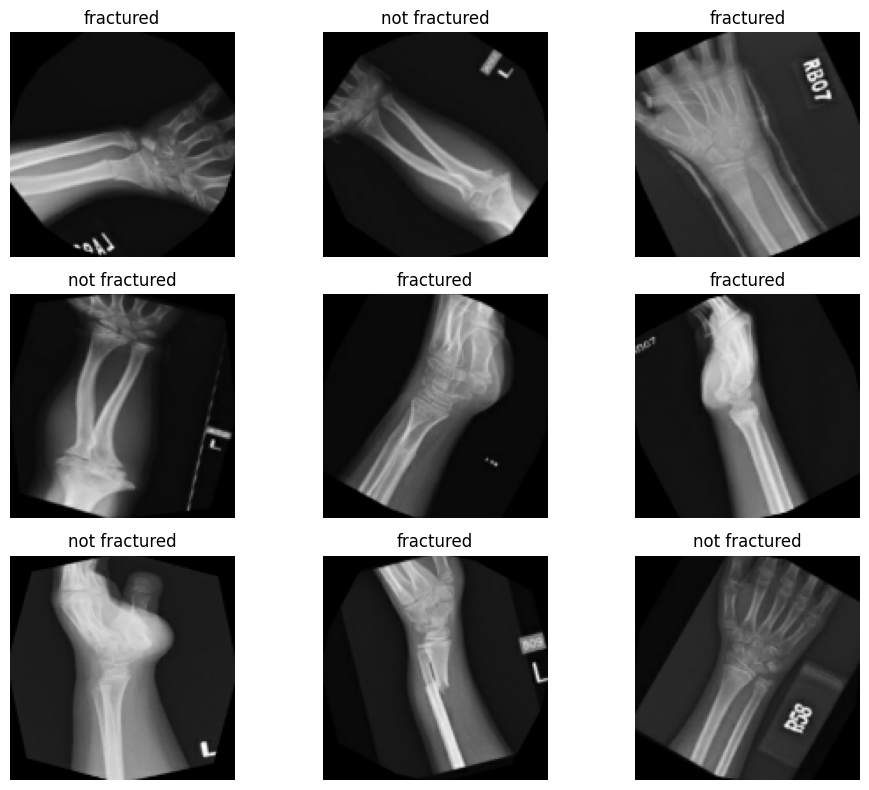

In [22]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        label_index = int(labels[i].numpy()[0])

        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()

## Build The CNN Model

In [23]:
model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Normalize pixel values from 0–255 to 0–1
    layers.Rescaling(1.0 / 255),

    # First convolution block
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Classification layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

## Train The Model

In [24]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "best_fracture_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - accuracy: 0.7264 - loss: 0.5254 - val_accuracy: 0.8021 - val_loss: 0.4937
Epoch 2/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9097 - loss: 0.2193 - val_accuracy: 0.7882 - val_loss: 0.4714
Epoch 3/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9628 - loss: 0.1005 - val_accuracy: 0.7257 - val_loss: 0.6765
Epoch 4/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9787 - loss: 0.0604 - val_accuracy: 0.8299 - val_loss: 0.3729
Epoch 5/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9835 - loss: 0.0467 - val_accuracy: 0.7396 - val_loss: 0.7063
Epoch 6/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.9873 - loss: 0.0374 - val_accuracy: 0.7153 - val_loss: 1.0011
Epoch 7/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9910 - loss: 0.0225 - val_accuracy: 0.7326 - val_loss: 1.4806
Epoch 8/30
277/277 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.9919 - loss: 0.0243 - val_a

## Plot accuracy and loss
Figure 1 — Training and validation accuracy

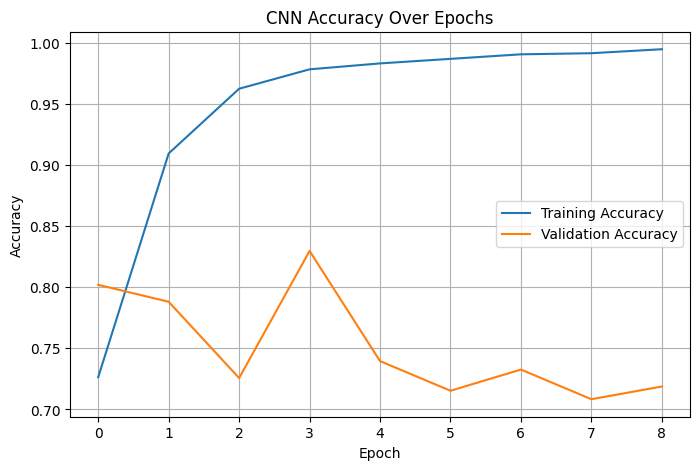

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("accuracy_curve.png", dpi=300)
plt.show()

Figure 2 — Training and validation loss

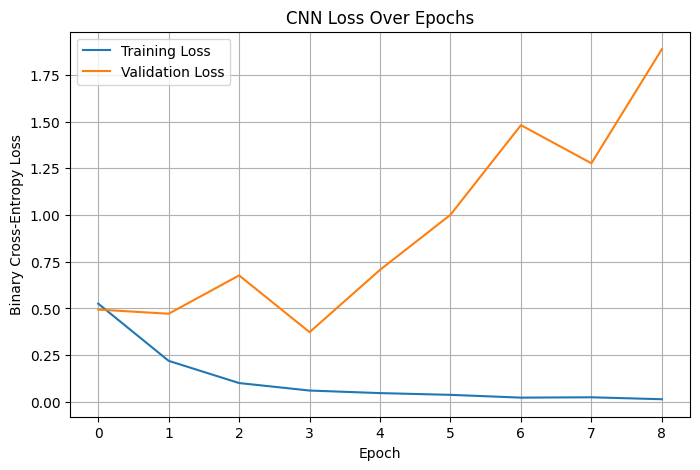

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png", dpi=300)
plt.show()

## Evaluate on the test dataset

In [27]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.7660 - loss: 0.5310
Test Loss: 0.5310
Test Accuracy: 76.60%


## calculate precision, recall, F1-score, and the confusion matrix.

Accuracy: 0.483974358974359

Classification Report:
               precision    recall  f1-score   support

    fractured       0.58      0.56      0.57       190
not fractured       0.35      0.37      0.36       122

     accuracy                           0.48       312
    macro avg       0.46      0.46      0.46       312
 weighted avg       0.49      0.48      0.49       312



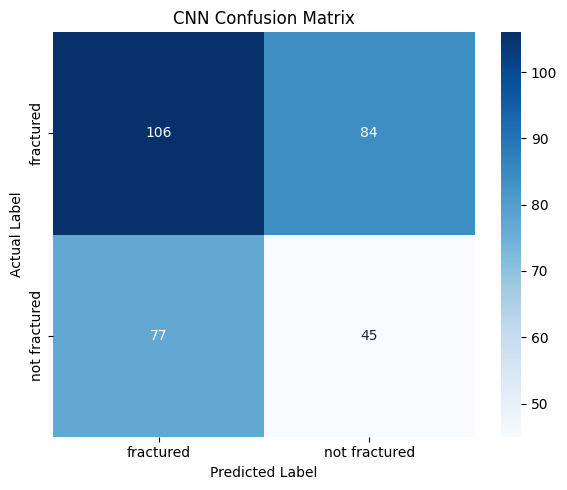

In [29]:
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Unbatch the dataset to get true labels instantly (No loop or asynchronous mismatch)
y_true = np.concatenate([y for x, y in test_ds.unbatch()]).astype(int)

# 2. Get predictions
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# 3. Print Metrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# 4. Generate & Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()


Predicted class: fractured
Probability for class 'not fractured': 0.0000


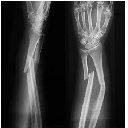

In [31]:
from IPython.display import display
from tensorflow.keras.utils import load_img, img_to_array

image_path = "/content/sample_x-ray.jpeg"
img = load_img(image_path, target_size=IMG_SIZE)
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

probability = float(model.predict(img_array, verbose=0)[0][0])

predicted_index = int(probability >= 0.5)
predicted_class = class_names[predicted_index]

print("Predicted class:", predicted_class)
print(f"Probability for class '{class_names[1]}': {probability:.4f}")

display(img)

## Save The Model

In [32]:
model.save("bone_fracture_detection_cnn.keras")
print("Model saved successfully.")

Model saved successfully.
